# Chapter 3: Dimensionality Reduction Techniques

This notebook covers Chapter 3 of *scikit-learn Cookbook* (3rd Edition, Packt). Datasets often have many features, and not all of them are useful. Too many features slow down training, make visualization impossible, and increase the risk of overfitting (the **curse of dimensionality**). Dimensionality reduction addresses this in two ways:
- **Feature extraction**: create a smaller set of new features that summarize the original ones (PCA, Kernel PCA, Truncated SVD, LDA, t-SNE).
- **Feature selection**: keep only the most useful original features (variance threshold, univariate selection, RFE, model-based selection).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_digits, load_breast_cancer, make_circles
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE
from sklearn.feature_selection import (VarianceThreshold, SelectKBest,
                                       f_classif, RFE, SelectFromModel)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline

## 1. The Data

Two built-in datasets are used:
- **Digits**: 1,797 images of handwritten digits (0 to 9), each 8×8 pixels, giving **64 features**.
- **Breast cancer**: 569 tumors with **30 numeric features** and a binary diagnosis.

Digits: (1797, 64)  Breast cancer: (569, 30)


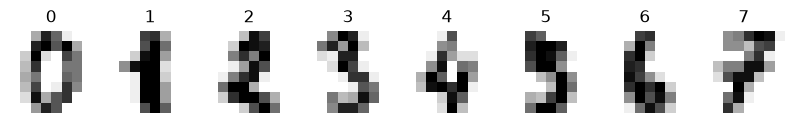

In [2]:
digits = load_digits()
X_dig, y_dig = digits.data, digits.target

cancer = load_breast_cancer()
X_can, y_can = cancer.data, cancer.target

print('Digits:', X_dig.shape, ' Breast cancer:', X_can.shape)

fig, axes = plt.subplots(1, 8, figsize=(10, 2))
for ax, img, label in zip(axes, digits.images, digits.target):
    ax.imshow(img, cmap='gray_r')
    ax.set_title(label)
    ax.axis('off')
plt.show()

## 2. Principal Component Analysis (PCA)

**PCA** finds new axes, called **principal components**, that capture as much of the variance in the data as possible:
- The first component is the direction of maximum variance.
- Each next component captures the most remaining variance while being **orthogonal** (uncorrelated) to the previous ones.

Mathematically, the components are the eigenvectors of the covariance matrix of the (centered) data, and the **explained variance ratio** of each component is its eigenvalue divided by the sum of all eigenvalues.

PCA is sensitive to feature scale, so data is usually **standardized first**. PCA is unsupervised: it does not use the labels.

Components needed for 90% of variance: 31 out of 64


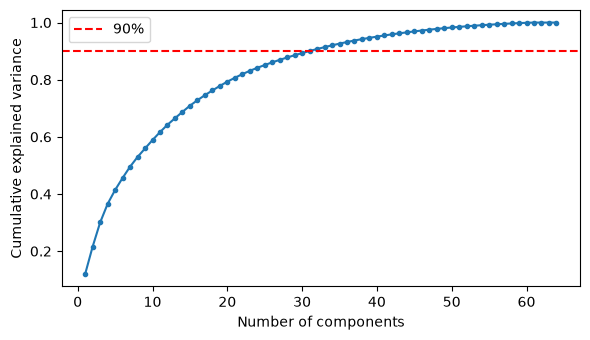

In [3]:
X_dig_std = StandardScaler().fit_transform(X_dig)

pca_full = PCA().fit(X_dig_std)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

n_90 = np.argmax(cum_var >= 0.90) + 1
print(f'Components needed for 90% of variance: {n_90} out of 64')

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, 65), cum_var, marker='.')
ax.axhline(0.90, color='red', linestyle='--', label='90%')
ax.set_xlabel('Number of components')
ax.set_ylabel('Cumulative explained variance')
ax.legend()
plt.tight_layout()
plt.show()

The cumulative explained variance curve rises quickly at first and then flattens: a fraction of the 64 components is enough to keep 90% of the information. Instead of choosing the number manually, PCA also accepts a variance target, e.g. `PCA(n_components=0.90)`.

### 2.1 Visualizing with Two Components

Variance explained by 2 components: 0.216


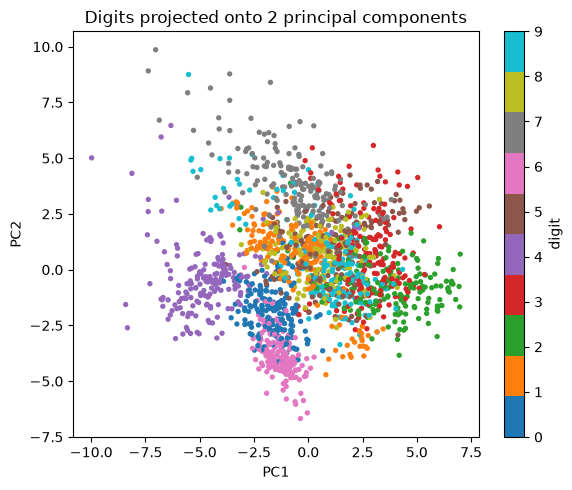

In [4]:
pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X_dig_std)
print('Variance explained by 2 components:', pca2.explained_variance_ratio_.sum().round(3))

fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(X_pca2[:, 0], X_pca2[:, 1], c=y_dig, cmap='tab10', s=8)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('Digits projected onto 2 principal components')
plt.colorbar(sc, ax=ax, label='digit')
plt.tight_layout()
plt.show()

With only two components, some digits form visible groups, but many overlap, because two components keep only a small share of the variance. PCA is a linear method, so it cannot fully separate classes that are arranged in complex, nonlinear ways.

### 2.2 PCA Inside a Pipeline

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X_dig, y_dig, test_size=0.25,
                                          random_state=42, stratify=y_dig)

full = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
reduced = make_pipeline(StandardScaler(), PCA(n_components=0.90),
                        LogisticRegression(max_iter=2000))

for name, pipe in [('All 64 features', full), ('PCA 90% variance', reduced)]:
    pipe.fit(X_tr, y_tr)
    print(f'{name:>17}: test accuracy = {pipe.score(X_te, y_te):.3f}')
print('Components kept by PCA:', reduced.named_steps['pca'].n_components_)

  All 64 features: test accuracy = 0.978
 PCA 90% variance: test accuracy = 0.949
Components kept by PCA: 31


The model with PCA uses far fewer features but reaches accuracy close to the model with all 64 pixels. This shows the main benefit of PCA: a much more compact representation with little loss of predictive information.

## 3. Kernel PCA and Truncated SVD

**Kernel PCA** applies the **kernel trick**: it implicitly maps the data into a higher-dimensional space (for example with an RBF kernel) and performs PCA there. This allows it to capture **nonlinear** structure that standard PCA misses.

**Truncated SVD** is similar to PCA but does not center the data, so it works directly on **sparse matrices** (such as text data with many zeros). In text analysis it is known as Latent Semantic Analysis (LSA).

The example uses two concentric circles, which no straight line can separate.

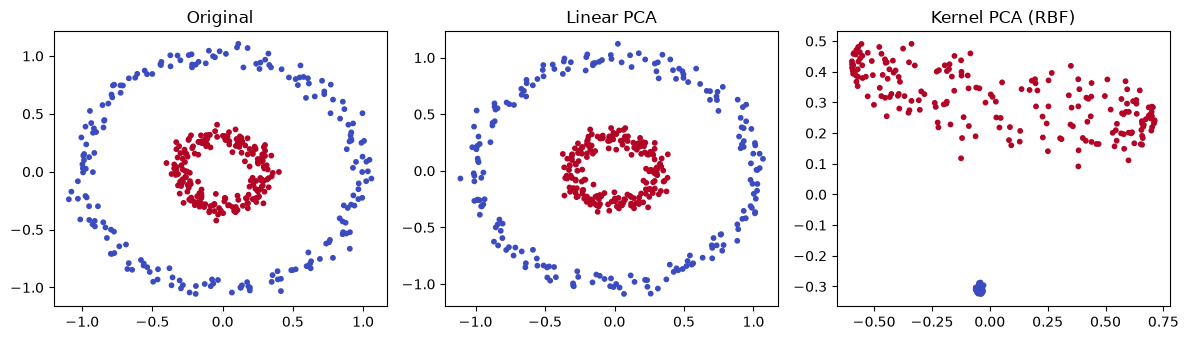

TruncatedSVD, variance explained by 10 components: 0.732


In [6]:
X_circ, y_circ = make_circles(n_samples=400, factor=0.3, noise=0.05, random_state=0)

X_lin = PCA(n_components=2).fit_transform(X_circ)
X_kpca = KernelPCA(n_components=2, kernel='rbf', gamma=10).fit_transform(X_circ)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, data, title in zip(axes, [X_circ, X_lin, X_kpca],
                           ['Original', 'Linear PCA', 'Kernel PCA (RBF)']):
    ax.scatter(data[:, 0], data[:, 1], c=y_circ, cmap='coolwarm', s=10)
    ax.set_title(title)
plt.tight_layout()
plt.show()

svd = TruncatedSVD(n_components=10, random_state=42).fit(X_dig)
print('TruncatedSVD, variance explained by 10 components:',
      svd.explained_variance_ratio_.sum().round(3))

Linear PCA only rotates the circles, so the two classes still overlap. Kernel PCA maps them into a space where the inner and outer circles become separable, which shows the value of nonlinear methods for curved structures.

## 4. Linear Discriminant Analysis (LDA)

Unlike PCA, **LDA is supervised**: it uses the labels. It finds the directions that **maximize the separation between classes** relative to the spread within each class:

$$\max_{\mathbf{w}} \frac{\mathbf{w}^T S_B \mathbf{w}}{\mathbf{w}^T S_W \mathbf{w}}$$

where $S_B$ is the between-class scatter and $S_W$ the within-class scatter. LDA can produce at most $C - 1$ components for $C$ classes (9 for the 10 digits).

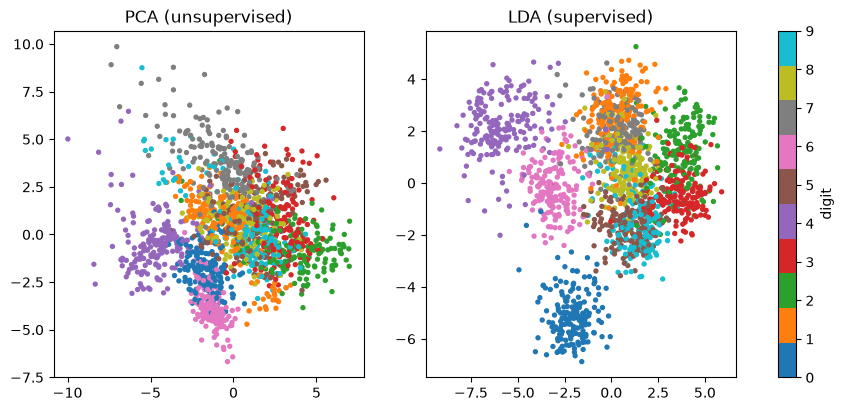

In [7]:
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_dig_std, y_dig)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, data, title in zip(axes, [X_pca2, X_lda], ['PCA (unsupervised)', 'LDA (supervised)']):
    sc = ax.scatter(data[:, 0], data[:, 1], c=y_dig, cmap='tab10', s=8)
    ax.set_title(title)
plt.colorbar(sc, ax=axes, label='digit')
plt.show()

With the same two dimensions, LDA separates the digits much better than PCA, because it uses the labels to find directions that distinguish the classes. PCA keeps the directions of largest variance, which are not necessarily the most useful for classification.

## 5. t-SNE for Visualization

**t-SNE** (t-distributed Stochastic Neighbor Embedding) is a nonlinear method designed for **visualization**. It tries to keep points that are close in the original space close in the 2D map. Key points:
- The `perplexity` parameter (roughly the number of neighbors considered) affects the result.
- Distances between clusters and cluster sizes in the plot are not meaningful.
- It has no `transform()` for new data and is slow on large datasets, so it is used for exploration, not as a preprocessing step for models.

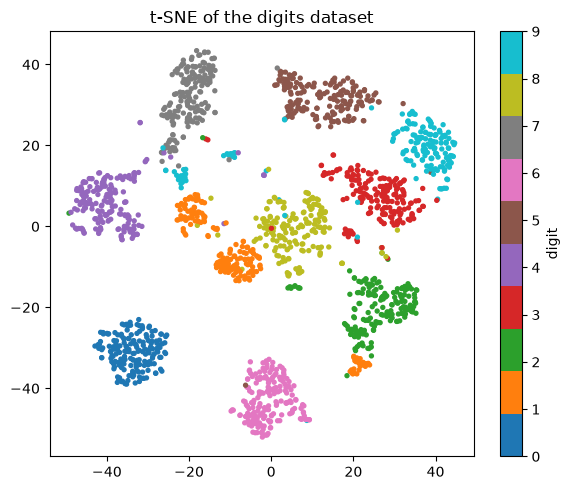

In [8]:
X_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_dig_std)

fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_dig, cmap='tab10', s=8)
ax.set_title('t-SNE of the digits dataset')
plt.colorbar(sc, ax=ax, label='digit')
plt.tight_layout()
plt.show()

## 6. Feature Selection

Feature selection keeps a subset of the **original** features, so the result stays interpretable.

- **VarianceThreshold**: removes features whose variance is below a threshold (e.g., constant pixels that are always 0).
- **SelectKBest**: scores each feature individually with a statistical test (e.g., ANOVA F-test with `f_classif`) and keeps the top $k$.
- **RFE (Recursive Feature Elimination)**: repeatedly fits a model and removes the weakest feature until $k$ remain.
- **SelectFromModel**: keeps features whose importance (coefficients or tree importances) is above a threshold.

In [9]:
vt = VarianceThreshold(threshold=0.0)
X_vt = vt.fit_transform(X_dig)
print(f'VarianceThreshold: {X_dig.shape[1]} -> {X_vt.shape[1]} digit pixels (constant pixels removed)')

VarianceThreshold: 64 -> 61 digit pixels (constant pixels removed)


In [10]:
feat_names = cancer.feature_names

kbest = SelectKBest(score_func=f_classif, k=5).fit(X_can, y_can)
print('SelectKBest (top 5):', list(feat_names[kbest.get_support()]))

rfe = RFE(LogisticRegression(max_iter=5000), n_features_to_select=5)
rfe.fit(StandardScaler().fit_transform(X_can), y_can)
print('RFE (5 features):    ', list(feat_names[rfe.support_]))

sfm = SelectFromModel(RandomForestClassifier(n_estimators=200, random_state=42),
                      threshold='median').fit(X_can, y_can)
print('SelectFromModel kept:', sfm.get_support().sum(), 'features (above median importance)')

SelectKBest (top 5): [np.str_('mean perimeter'), np.str_('mean concave points'), np.str_('worst radius'), np.str_('worst perimeter'), np.str_('worst concave points')]
RFE (5 features):     [np.str_('radius error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst area'), np.str_('worst concave points')]
SelectFromModel kept: 15 features (above median importance)


In [11]:
for name, pipe in [
    ('All 30 features', make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))),
    ('SelectKBest k=5', make_pipeline(StandardScaler(), SelectKBest(f_classif, k=5),
                                      LogisticRegression(max_iter=5000))),
]:
    scores = cross_val_score(pipe, X_can, y_can, cv=5)
    print(f'{name:>16}: CV accuracy = {scores.mean():.3f}')

 All 30 features: CV accuracy = 0.981
 SelectKBest k=5: CV accuracy = 0.949


Different selection methods pick partly different features because they measure usefulness differently: SelectKBest looks at each feature alone, while RFE and SelectFromModel account for how features work together in a model. A model with only 5 selected features stays close to the accuracy of the full model, while being simpler and easier to interpret. Selection is placed inside the pipeline so that it is learned only from the training folds.

## Chapter Summary

- High-dimensional data is slow to process, hard to visualize, and prone to overfitting, so reducing dimensions is often useful.
- **PCA** creates uncorrelated components that keep the maximum variance; the cumulative explained variance helps choose how many to keep. Data should be standardized first.
- **Kernel PCA** captures nonlinear structure using the kernel trick, and **Truncated SVD** works directly on sparse data.
- **LDA** is supervised and finds directions that best separate classes, giving at most $C - 1$ components.
- **t-SNE** is a nonlinear visualization tool that reveals cluster structure, but it is not used as a preprocessing step for models.
- **Feature selection** keeps original features: `VarianceThreshold` removes constant features, `SelectKBest` uses univariate tests, `RFE` removes features recursively, and `SelectFromModel` uses model importances.
- Placing reduction and selection inside a **pipeline** prevents data leakage during evaluation.